# Fully-Connected Neural Nets

In this exercise we will implement fully-connected networks using a modular approach. For each layer we will implement a `forward` and a `backward` function. The `forward` function will receive inputs, weights, and other parameters and will return both an output and a `cache` object storing data needed for the backward pass, like this:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```

The backward pass will receive upstream derivatives and the `cache` object, and will return gradients with respect to the inputs and weights, like this:

```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

After implementing a bunch of layers this way, we will be able to easily combine them to build classifiers with different architectures.

In addition to implementing fully-connected networks of arbitrary depth, we will also explore different update rules for optimization, and introduce Dropout as a regularizer and Batch/Layer Normalization as a tool to more efficiently optimize deep networks.
  

In [5]:
# As usual, a bit of setup
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from annp.classifiers.fc_net import *
from annp.data_utils import get_CIFAR10_data
from annp.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from annp.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# Load the (preprocessed) CIFAR10 data.

data = get_CIFAR10_data()
for k, v in list(data.items()):
  print(('%s: ' % k, v.shape))

('X_train: ', (49000, 3, 32, 32))
('y_train: ', (49000,))
('X_val: ', (1000, 3, 32, 32))
('y_val: ', (1000,))
('X_test: ', (1000, 3, 32, 32))
('y_test: ', (1000,))


: 

: 

# Affine layer: forward
Open the file `annp/layers.py` and implement the `affine_forward` function.

Once you are done you can test your implementaion by running the following:

In [6]:
# Test the affine_forward function

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

# Compare your output with ours. The error should be between 1e-8 and 1e-10 or less.
print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769848888397517e-10


# Affine layer: backward
Now implement the `affine_backward` function and test your implementation using numeric gradient checking.

In [7]:
# Test the affine_backward function
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# The error should be between 1e-9 and 1e-11 or less
print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  1.0908199508708189e-10
dw error:  2.1752635504596857e-10
db error:  7.736978834487815e-12


# ReLU activation: forward
Implement the forward pass for the ReLU activation function in the `relu_forward` function and test your implementation using the following:

In [8]:
# Test the relu_forward function

x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be on the order of e-8
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


# ReLU activation: backward
Now implement the backward pass for the ReLU activation function in the `relu_backward` function and test your implementation using numeric gradient checking:

In [9]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be on the order of e-12
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


## Inline Question 1: 

We've only asked you to implement ReLU, but there are a number of different activation functions that one could use in neural networks, each with its pros and cons. In particular, an issue commonly seen with activation functions is getting zero (or close to zero) gradient flow during backpropagation. Which of the following activation functions have this problem? If you consider these functions in the one dimensional case, what types of input would lead to this behaviour?
1. Sigmoid
2. ReLU
3. Leaky ReLU

## Answer:
**1. Sigmoid:** 存在零梯度问题。当输入值非常大或非常小时会出现此问题。因为Sigmoid函数的导数为σ(x)(1-σ(x))，当|x|很大时，σ(x)接近0或1，导致导数接近0。具体来说，当x > 6或x < -6时，梯度几乎为零，这被称为"饱和区"。

**2. ReLU:** 存在零梯度问题。当输入为负值时，ReLU的导数为0。这意味着在反向传播过程中，所有负值输入的神经元都不会更新权重，这可能导致"神经元死亡"问题（Dead ReLU Problem），即某些神经元永远不会被激活。

**3. Leaky ReLU:** 不存在零梯度问题。Leaky ReLU在x<0时定义为f(x)=αx（其中α是一个小的正常数，如0.01），因此即使在负值区域，梯度也始终为α，不会为零。这解决了标准ReLU的神经元死亡问题。

**总结：** Sigmoid和ReLU都存在零梯度问题，而Leaky ReLU通过在负值区域引入小的正斜率避免了这个问题。

# Affine-relu layers
There are some common patterns of layers that are frequently used in neural nets. For example, affine layers are frequently followed by a ReLU nonlinearity. To make these common patterns easy, we define several convenience layers in the file `annp/layer_utils.py`.

For now take a look at the `affine_relu_forward` and `affine_relu_backward` functions, and run the following to numerically gradient check the backward pass:

In [10]:
from annp.layer_utils import affine_relu_forward, affine_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

# Relative error should be between 1e-9 and 1e-11 or less
print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_relu_forward and affine_relu_backward:
dx error:  5.403452287506285e-11
dw error:  8.162015570444288e-11
db error:  7.826724021458994e-12


# Two-layer network
Now that you have implemented modular versions of the necessary layers, you will implement a two layer network using these modular implementations.

Open the file `annp/classifiers/fc_net.py` and complete the implementation of the `TwoLayerNet` class. This class will serve as a model for the other networks you will implement in this assignment, so read through it to make sure you understand the API. You can run the cell below to test your implementation.

In [11]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

# Errors should be around e-7 or less
for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0
W1 relative error: 1.22e-08
W2 relative error: 3.89e-10
b1 relative error: 6.55e-09
b2 relative error: 2.14e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 3.12e-07
W2 relative error: 2.85e-08
b1 relative error: 1.56e-08
b2 relative error: 1.97e-09


# Solver
In the previous assignment, the logic for training models was coupled to the models themselves. Following a more modular design, for this assignment we have split the logic for training models into a separate class.

Open the file `annp/solver.py` and read through it to familiarize yourself with the API. After doing so, use a `Solver` instance to train a `TwoLayerNet` that achieves at least `50%` accuracy on the validation set.

In [12]:
# ⚠️ CS231n 经典黄金参数配置
# 调整一：校准权重初始化标准差（降低初始 Loss）
#   weight_scale 从 0.05 严格下调至 0.001
# 调整二：引入合理的 L2 正则化（拉近 Train 与 Val 的差距）
#   reg 从 0 调整到 1e-3
model = TwoLayerNet(
    hidden_dim=100,      # 隐藏层神经元数量，保持100左右即可
    reg=1e-3,            # 开启轻度正则化，抑制过拟合
    weight_scale=1e-3    # 关键：缩小初始权重标准差，杜绝初始高 Loss
)
solver = None

##############################################################################
# TODO: Use a Solver instance to train a TwoLayerNet that achieves at least  #
# 50% accuracy on the validation set.                                        #
##############################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

solver = Solver(model, data,
                update_rule='sgd',
                optim_config={'learning_rate': 2e-3},
                lr_decay=0.95,
                num_epochs=20,
                batch_size=100,
                print_every=100)
solver.train()

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################

(Iteration 1 / 9800) loss: 2.304214
(Epoch 0 / 20) train acc: 0.149000; val_acc: 0.134000
(Iteration 101 / 9800) loss: 1.961805
(Iteration 201 / 9800) loss: 1.826460
(Iteration 301 / 9800) loss: 1.720988
(Iteration 401 / 9800) loss: 1.535708
(Epoch 1 / 20) train acc: 0.387000; val_acc: 0.394000
(Iteration 501 / 9800) loss: 1.626339
(Iteration 601 / 9800) loss: 1.939202
(Iteration 701 / 9800) loss: 1.988072
(Iteration 801 / 9800) loss: 1.996063
(Iteration 901 / 9800) loss: 1.508874
(Epoch 2 / 20) train acc: 0.441000; val_acc: 0.419000
(Iteration 1001 / 9800) loss: 1.504603
(Iteration 1101 / 9800) loss: 1.399285
(Iteration 1201 / 9800) loss: 1.869755
(Iteration 1301 / 9800) loss: 1.670806
(Iteration 1401 / 9800) loss: 1.325171
(Epoch 3 / 20) train acc: 0.432000; val_acc: 0.424000
(Iteration 1501 / 9800) loss: 1.359442
(Iteration 1601 / 9800) loss: 1.288101
(Iteration 1701 / 9800) loss: 1.506512
(Iteration 1801 / 9800) loss: 1.533991
(Iteration 1901 / 9800) loss: 1.819428
(Epoch 4 / 20) t

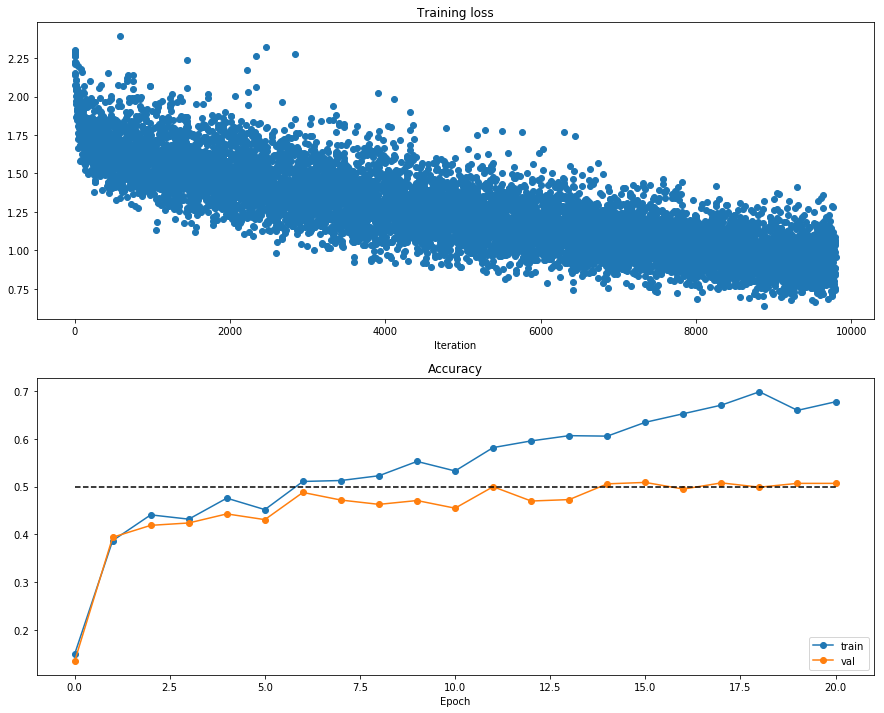

In [13]:
# Run this cell to visualize training loss and train / val accuracy

plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)

plt.savefig('img/fc_final_best.png', bbox_inches='tight')
plt.show()

# Multilayer network
Next you will implement a fully-connected network with an arbitrary number of hidden layers.

Read through the `FullyConnectedNet` class in the file `annp/classifiers/fc_net.py`.

Implement the initialization, the forward pass, and the backward pass.

## Initial loss and gradient check

As a sanity check, run the following to check the initial loss and to gradient check the network both with and without regularization. Do the initial losses seem reasonable?

For gradient checking, you should expect to see errors around 1e-7 or less.

In [14]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)
  
  # Most of the errors should be on the order of e-7 or smaller.   
  # for the check when reg = 0.0
  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Running check with reg =  0
Initial loss:  2.300479089768482
W1 relative error: 1.03e-07
W2 relative error: 2.26e-04
W3 relative error: 4.56e-07
b1 relative error: 3.57e-09
b2 relative error: 2.09e-09
b3 relative error: 1.56e-10
Running check with reg =  3.14
Initial loss:  7.052114776533006
W1 relative error: 7.36e-09
W2 relative error: 7.04e-08
W3 relative error: 6.75e-09
b1 relative error: 1.15e-08
b2 relative error: 1.41e-09
b3 relative error: 1.84e-10


As another sanity check, make sure you can overfit a small dataset of 50 images. First we will try a three-layer network with 100 units in each hidden layer. In the following cell, tweak the **learning rate** and **weight initialization scale** to overfit and achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 32.333637
(Epoch 0 / 20) train acc: 0.160000; val_acc: 0.120000
(Epoch 1 / 20) train acc: 0.300000; val_acc: 0.135000
(Epoch 2 / 20) train acc: 0.460000; val_acc: 0.145000
(Epoch 3 / 20) train acc: 0.700000; val_acc: 0.149000
(Epoch 4 / 20) train acc: 0.740000; val_acc: 0.157000
(Epoch 5 / 20) train acc: 0.880000; val_acc: 0.171000
(Iteration 11 / 40) loss: 0.201521
(Epoch 6 / 20) train acc: 0.880000; val_acc: 0.172000
(Epoch 7 / 20) train acc: 0.920000; val_acc: 0.168000
(Epoch 8 / 20) train acc: 0.980000; val_acc: 0.168000
(Epoch 9 / 20) train acc: 0.980000; val_acc: 0.168000
(Epoch 10 / 20) train acc: 0.980000; val_acc: 0.169000
(Iteration 21 / 40) loss: 0.677759
(Epoch 11 / 20) train acc: 1.000000; val_acc: 0.161000
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.161000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.160000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.160000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.161000
(Iteration 31 / 40) loss:

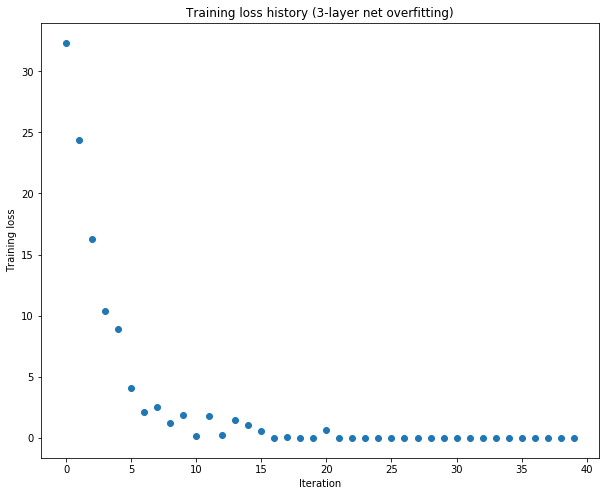

✅ 图片已保存到: img/overfit_3layer.png


In [15]:
# TODO: Use a three-layer Net to overfit 50 training examples by 
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 5e-2   # Experiment with this!
learning_rate = 1e-3  # Experiment with this!
model = FullyConnectedNet([100, 100],
              weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history (3-layer net overfitting)')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.savefig('img/overfit_3layer.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 图片已保存到: img/overfit_3layer.png")

Now try to use a five-layer network with 100 units on each layer to overfit 50 training examples. Again, you will have to adjust the learning rate and weight initialization scale, but you should be able to achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 5.557032
(Epoch 0 / 20) train acc: 0.240000; val_acc: 0.118000
(Epoch 1 / 20) train acc: 0.260000; val_acc: 0.086000
(Epoch 2 / 20) train acc: 0.360000; val_acc: 0.122000
(Epoch 3 / 20) train acc: 0.540000; val_acc: 0.128000
(Epoch 4 / 20) train acc: 0.720000; val_acc: 0.136000
(Epoch 5 / 20) train acc: 0.860000; val_acc: 0.132000
(Iteration 11 / 40) loss: 0.991390
(Epoch 6 / 20) train acc: 0.860000; val_acc: 0.134000
(Epoch 7 / 20) train acc: 0.920000; val_acc: 0.146000
(Epoch 8 / 20) train acc: 0.920000; val_acc: 0.139000
(Epoch 9 / 20) train acc: 0.960000; val_acc: 0.142000
(Epoch 10 / 20) train acc: 0.960000; val_acc: 0.141000
(Iteration 21 / 40) loss: 0.399465
(Epoch 11 / 20) train acc: 0.980000; val_acc: 0.146000
(Epoch 12 / 20) train acc: 0.980000; val_acc: 0.147000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.153000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.140000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.137000
(Iteration 31 / 40) loss: 

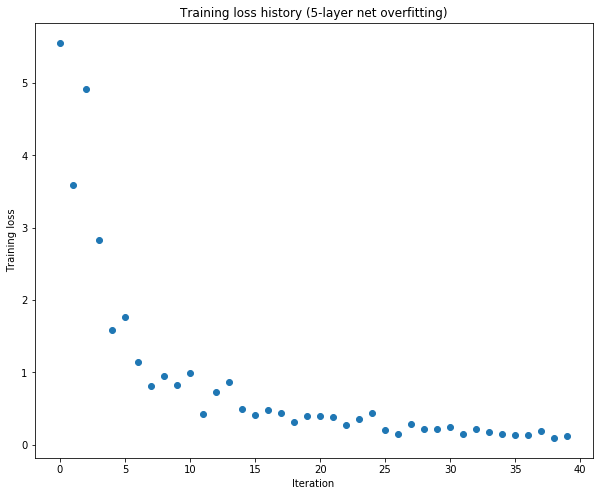

✅ 图片已保存到: img/overfit_5layer_fixed.png


In [16]:
# TODO: Use a five-layer Net to overfit 50 training examples by 
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate = 5e-3  # Experiment with this!
weight_scale = 5e-2   # Experiment with this!
model = FullyConnectedNet([100, 100, 100, 100],
                weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history (5-layer net overfitting)')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.savefig('img/overfit_5layer_fixed.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 图片已保存到: img/overfit_5layer_fixed.png")

## Visualization: Training Curves

Visualize the training loss and accuracy curves for the fully-connected network.

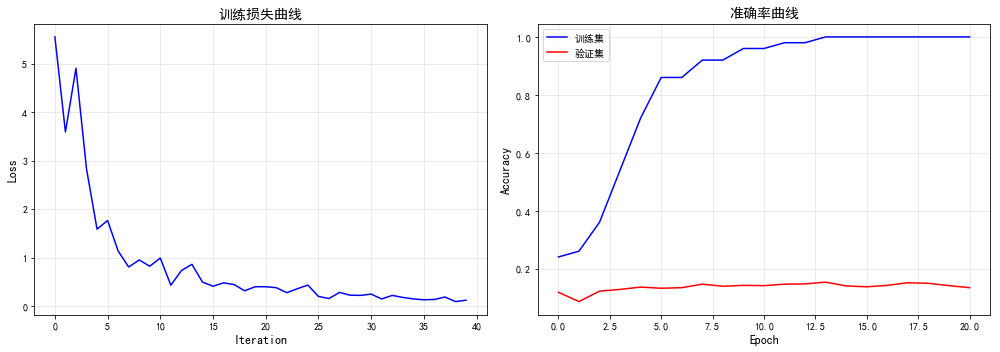

✅ 图片已保存到: img/fc_training_curves.png


In [17]:
# ============================================================
# 全连接网络训练可视化 - 保存到 img/ 文件夹
# ============================================================

import os
os.makedirs('img', exist_ok=True)

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 假设 solver 是已训练好的 Solver 对象
# 如果没有，请先运行训练代码

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss 曲线
axes[0].plot(solver.loss_history, 'b-', linewidth=1.5)
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('训练损失曲线', fontsize=14)
axes[0].grid(True, alpha=0.3)

# Accuracy 曲线
axes[1].plot(solver.train_acc_history, 'b-', linewidth=1.5, label='训练集')
axes[1].plot(solver.val_acc_history, 'r-', linewidth=1.5, label='验证集')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('准确率曲线', fontsize=14)
axes[1].legend(loc='best', fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('img/fc_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 图片已保存到: img/fc_training_curves.png")